# OREX vs NEO-REX: raw and simple rescaled x

Notebook pulito con fit guida sui plot riscalati.

1. Plot grezzi di accettanza e lavoro in funzione di `$n_{\mathrm{steps}}^{\mathrm{eff}}=\max(1,n_{\mathrm{steps}})$`.
2. Plot usando come ascissa principale `$x=n_{\mathrm{steps}}^{\mathrm{eff}}(N_r-1)^2/V_{\rm def}$`, con `$V_{\rm def}=d_{\rm def}^3$`.
3. Fit guida per algoritmo: `$W=C/x$` e accettanza con `$A\exp(-B/x)$` oppure `$A\,\mathrm{erfc}(B/\sqrt{x})$`.

In [40]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.special import erfc, erfcinv

plt.style.use('seaborn-v0_8-whitegrid')

BASE_DIR = Path('plot/orex_recovered_from_txt')
if not BASE_DIR.exists():
    BASE_DIR = Path('.')

OREX_CSV = BASE_DIR / 'recovered_orex_metrics.csv'
OREX_D3_CSV = BASE_DIR / 'recovered_orex_d3_metrics.csv'
NEOREX_CSV = BASE_DIR / 'recovered_neorex_eval_metrics.csv'
OUT_DIR = BASE_DIR

OREX_CSV, OREX_D3_CSV, NEOREX_CSV, OUT_DIR

(PosixPath('recovered_orex_metrics.csv'),
 PosixPath('recovered_orex_d3_metrics.csv'),
 PosixPath('recovered_neorex_eval_metrics.csv'),
 PosixPath('.'))

In [41]:
def infer_defect_size(frame, default=2):
    if 'defect_size' in frame.columns:
        defect_size = pd.to_numeric(frame['defect_size'], errors='coerce')
    else:
        defect_size = pd.Series(np.nan, index=frame.index, dtype=float)
    source = pd.Series('', index=frame.index, dtype=object)
    for col in ['study_name', 'output_dir', 'wandb_run_name', 'run_name']:
        if col in frame.columns:
            source = source + ' ' + frame[col].fillna('').astype(str)
    parsed = source.str.extract(r'_d(\d+)(?:_|$)', expand=False)
    parsed = pd.to_numeric(parsed, errors='coerce')
    return defect_size.fillna(parsed).fillna(default).astype(int)


def load_metrics(path, algorithm, default_defect_size=2):
    frame = pd.read_csv(path)
    numeric_cols = [
        'world_size', 'nreplicas', 'nsteps', 'swap_acceptance', 'total_accepted',
        'total_proposed', 'work_mean', 'work_sem', 'work_count',
        'thermalization_s', 'measurement_s', 'total_s', 'flow_applied_updates',
        'defect_size', 'defect_volume',
    ]
    for col in numeric_cols:
        if col in frame.columns:
            frame[col] = pd.to_numeric(frame[col], errors='coerce')
    if 'swap_acceptance_sem' not in frame.columns:
        frame['swap_acceptance_sem'] = np.sqrt(
            frame['swap_acceptance'] * (1.0 - frame['swap_acceptance']) / frame['total_proposed']
        )
    frame['defect_size'] = infer_defect_size(frame, default=default_defect_size)
    frame['defect_volume'] = frame['defect_size'] ** 3
    frame['algorithm'] = algorithm
    return frame.sort_values(['defect_volume', 'nreplicas', 'nsteps']).reset_index(drop=True)

orex_frames = [load_metrics(OREX_CSV, 'OREX', default_defect_size=2)]
if OREX_D3_CSV.exists():
    orex_frames.append(load_metrics(OREX_D3_CSV, 'OREX', default_defect_size=3))
orex = pd.concat(orex_frames, ignore_index=True, sort=False)
neorex = load_metrics(NEOREX_CSV, 'NEO-REX pretrained', default_defect_size=2)

# NEO-REX non ha un vero punto nsteps=0 nel dataset corrente.
data = pd.concat([orex, neorex], ignore_index=True, sort=False)
data['nsteps_eff'] = data['nsteps'].clip(lower=1)
data['x_rescaled'] = data['nsteps_eff'] * (data['nreplicas'] - 1.0) ** 2 / data['defect_volume']
data['x_sqrt'] = np.sqrt(data['x_rescaled'])

data[['algorithm', 'defect_size', 'defect_volume', 'nreplicas', 'nsteps', 'nsteps_eff', 'x_rescaled', 'x_sqrt', 'swap_acceptance', 'swap_acceptance_sem', 'work_mean', 'work_sem']]

,algorithm,defect_size,defect_volume,nreplicas,nsteps,nsteps_eff,x_rescaled,x_sqrt,swap_acceptance,swap_acceptance_sem,work_mean,work_sem
0,OREX,2,8,4,0,1,1.125000,1.060660,0.010286,0.000515,15.468660,0.035250
1,OREX,2,8,4,2,2,2.250000,1.500000,0.058750,0.001200,7.980036,0.023260
2,OREX,2,8,4,4,4,4.500000,2.121320,0.166354,0.001900,4.105233,0.015910
3,OREX,2,8,4,6,6,6.750000,2.598076,0.259323,0.002237,2.735193,0.012750
4,OREX,2,8,4,8,8,9.000000,3.000000,0.322604,0.002386,2.069812,0.010870
5,OREX,2,8,8,0,1,6.125000,2.474874,0.247355,0.001441,2.858547,0.008452
6,OREX,2,8,8,2,2,12.250000,3.500000,0.423315,0.001651,1.362651,0.005909
7,OREX,2,8,8,4,4,24.500000,4.949747,0.557723,0.001659,0.715913,0.004192
8,OREX,2,8,8,6,6,36.750000,6.062178,0.625156,0.001617,0.492444,0.003431
9,OREX,2,8,8,8,8,49.000000,7.000000,0.667913,0.001573,0.381195,0.002983


In [42]:
replica_colors = {
    4: 'tab:blue',
    8: 'tab:orange',
    12: 'tab:green',
    16: 'tab:red',
}

algorithm_styles = {
    'OREX': {'marker': 'o'},
    'NEO-REX pretrained': {'marker': 's'},
}

fit_line_styles = {
    'OREX': {'color': '0.15', 'linestyle': '-'},
    'NEO-REX pretrained': {'color': '0.15', 'linestyle': '--'},
}


def by_algorithm_replica(frame):
    group_cols = ['algorithm', 'nreplicas', 'defect_volume'] if 'defect_volume' in frame.columns else ['algorithm', 'nreplicas']
    for keys, sub in frame.groupby(group_cols, sort=True):
        if len(group_cols) == 3:
            algorithm, nrep, vdef = keys
        else:
            algorithm, nrep = keys
            vdef = np.nan
        yield algorithm, int(nrep), int(vdef) if np.isfinite(vdef) else vdef, sub.sort_values('nsteps')


def plot_style(algorithm, nrep, vdef=None):
    base = algorithm_styles.get(algorithm, {'marker': 'o'})
    color = replica_colors.get(int(nrep), None)
    filled = not (pd.notna(vdef) and int(vdef) != 8)
    return {
        'marker': base['marker'],
        'color': color,
        'markerfacecolor': color if filled else 'none',
        'markeredgewidth': 1.0 if filled else 1.7,
    }


def fit_line_style(algorithm):
    return fit_line_styles.get(algorithm, {'color': '0.15', 'linestyle': ':'})


def savefig(fig, name):
    png = OUT_DIR / f'{name}.png'
    pdf = OUT_DIR / f'{name}.pdf'
    fig.savefig(png, dpi=180, bbox_inches='tight')
    fig.savefig(pdf, bbox_inches='tight')
    return png, pdf

def work_model(x, C):
    x = np.asarray(x, dtype=float)
    return C / x


def acceptance_model(x, A, B):
    x = np.asarray(x, dtype=float)
    return A * np.exp(-B / x)


def positive_sigma(values, fallback=1.0):
    sigma = np.asarray(values, dtype=float)
    good = np.isfinite(sigma) & (sigma > 0)
    if good.all():
        return sigma
    if good.any():
        fill = np.nanmedian(sigma[good])
    else:
        fill = fallback
    return np.where(good, sigma, fill)


def fit_work_by_algorithm(frame):
    rows = []
    for algorithm, sub in frame.groupby('algorithm', sort=True):
        fit = sub[np.isfinite(sub['x_rescaled']) & np.isfinite(sub['work_mean']) & (sub['x_rescaled'] > 0)].copy()
        x = fit['x_rescaled'].to_numpy(dtype=float)
        y = fit['work_mean'].to_numpy(dtype=float)
        sigma = positive_sigma(fit['work_sem'].to_numpy(dtype=float), fallback=np.nanstd(y))
        popt, pcov = curve_fit(
            work_model,
            x,
            y,
            sigma=sigma,
            absolute_sigma=True,
            p0=[np.nanmedian(x * y)],
            bounds=(0.0, np.inf),
        )
        rows.append({'algorithm': algorithm, 'C_work': popt[0], 'C_work_sem': np.sqrt(pcov[0, 0])})
    return pd.DataFrame(rows)


def fit_acceptance_by_algorithm(frame):
    rows = []
    for algorithm, sub in frame.groupby('algorithm', sort=True):
        fit = sub[np.isfinite(sub['x_rescaled']) & np.isfinite(sub['swap_acceptance']) & (sub['x_rescaled'] > 0)].copy()
        x = fit['x_rescaled'].to_numpy(dtype=float)
        y = np.clip(fit['swap_acceptance'].to_numpy(dtype=float), 1e-12, 1.0 - 1e-12)
        sigma = positive_sigma(fit['swap_acceptance_sem'].to_numpy(dtype=float), fallback=np.nanstd(y))
        p0 = [min(0.99, max(0.05, np.nanmax(y))), max(1e-6, np.nanmedian(x))]
        popt, pcov = curve_fit(
            acceptance_model,
            x,
            y,
            sigma=sigma,
            absolute_sigma=True,
            p0=p0,
            bounds=([0.0, 0.0], [1.0, np.inf]),
            maxfev=20000,
        )
        rows.append({
            'algorithm': algorithm,
            'A_acceptance': popt[0],
            'B_acceptance': popt[1],
            'A_acceptance_sem': np.sqrt(pcov[0, 0]),
            'B_acceptance_sem': np.sqrt(pcov[1, 1]),
        })
    return pd.DataFrame(rows)


def acceptance_residuals(frame, fits):
    rows = []
    for _, fit in fits.iterrows():
        sub = frame[frame['algorithm'] == fit['algorithm']].copy()
        pred = acceptance_model(sub['x_rescaled'], fit['A_acceptance'], fit['B_acceptance'])
        sigma = positive_sigma(sub['swap_acceptance_sem'].to_numpy(dtype=float), fallback=1.0)
        out = sub[['algorithm', 'nreplicas', 'nsteps', 'nsteps_eff', 'x_rescaled', 'swap_acceptance', 'swap_acceptance_sem']].copy()
        out['acceptance_fit'] = pred
        out['acceptance_residual'] = out['swap_acceptance'] - out['acceptance_fit']
        out['acceptance_pull'] = out['acceptance_residual'] / sigma
        rows.append(out)
    return pd.concat(rows, ignore_index=True).sort_values(['algorithm', 'nreplicas', 'nsteps'])


def acceptance_erfc_model(x, A, B):
    x = np.asarray(x, dtype=float)
    return A * erfc(B / np.sqrt(x))


def fit_acceptance_erfc_by_algorithm(frame):
    rows = []
    for algorithm, sub in frame.groupby('algorithm', sort=True):
        fit = sub[np.isfinite(sub['x_rescaled']) & np.isfinite(sub['swap_acceptance']) & (sub['x_rescaled'] > 0)].copy()
        x = fit['x_rescaled'].to_numpy(dtype=float)
        y = np.clip(fit['swap_acceptance'].to_numpy(dtype=float), 1e-12, 1.0 - 1e-12)
        sigma = positive_sigma(fit['swap_acceptance_sem'].to_numpy(dtype=float), fallback=np.nanstd(y))
        p0 = [min(0.99, max(0.05, np.nanmax(y))), 1.0]
        popt, pcov = curve_fit(
            acceptance_erfc_model,
            x,
            y,
            sigma=sigma,
            absolute_sigma=True,
            p0=p0,
            bounds=([0.0, 0.0], [1.0, np.inf]),
            maxfev=20000,
        )
        rows.append({
            'algorithm': algorithm,
            'A_erfc_acceptance': popt[0],
            'B_erfc_acceptance': popt[1],
            'A_erfc_acceptance_sem': np.sqrt(pcov[0, 0]),
            'B_erfc_acceptance_sem': np.sqrt(pcov[1, 1]),
        })
    return pd.DataFrame(rows)


def acceptance_erfc_residuals(frame, fits):
    rows = []
    for _, fit in fits.iterrows():
        sub = frame[frame['algorithm'] == fit['algorithm']].copy()
        pred = acceptance_erfc_model(sub['x_rescaled'], fit['A_erfc_acceptance'], fit['B_erfc_acceptance'])
        sigma = positive_sigma(sub['swap_acceptance_sem'].to_numpy(dtype=float), fallback=1.0)
        out = sub[['algorithm', 'nreplicas', 'nsteps', 'nsteps_eff', 'x_rescaled', 'swap_acceptance', 'swap_acceptance_sem']].copy()
        out['acceptance_erfc_fit'] = pred
        out['acceptance_erfc_residual'] = out['swap_acceptance'] - out['acceptance_erfc_fit']
        out['acceptance_erfc_pull'] = out['acceptance_erfc_residual'] / sigma
        rows.append(out)
    return pd.concat(rows, ignore_index=True).sort_values(['algorithm', 'nreplicas', 'nsteps'])


def sqrt_work_model(x, C):
    x = np.asarray(x, dtype=float)
    return C / (x * x)


def sqrt_acceptance_erfc_model(x, A, B):
    x = np.asarray(x, dtype=float)
    return A * erfc(B / x)


def fit_sqrt_work_by_algorithm(frame):
    rows = []
    for algorithm, sub in frame.groupby('algorithm', sort=True):
        fit = sub[np.isfinite(sub['x_sqrt']) & np.isfinite(sub['work_mean']) & (sub['x_sqrt'] > 0)].copy()
        x = fit['x_sqrt'].to_numpy(dtype=float)
        y = fit['work_mean'].to_numpy(dtype=float)
        sigma = positive_sigma(fit['work_sem'].to_numpy(dtype=float), fallback=np.nanstd(y))
        popt, pcov = curve_fit(
            sqrt_work_model,
            x,
            y,
            sigma=sigma,
            absolute_sigma=True,
            p0=[np.nanmedian(x * x * y)],
            bounds=(0.0, np.inf),
        )
        rows.append({'algorithm': algorithm, 'C_sqrt_work': popt[0], 'C_sqrt_work_sem': np.sqrt(pcov[0, 0])})
    return pd.DataFrame(rows)


def fit_sqrt_acceptance_erfc_by_algorithm(frame):
    rows = []
    for algorithm, sub in frame.groupby('algorithm', sort=True):
        fit = sub[np.isfinite(sub['x_sqrt']) & np.isfinite(sub['swap_acceptance']) & (sub['x_sqrt'] > 0)].copy()
        x = fit['x_sqrt'].to_numpy(dtype=float)
        y = np.clip(fit['swap_acceptance'].to_numpy(dtype=float), 1e-12, 1.0 - 1e-12)
        sigma = positive_sigma(fit['swap_acceptance_sem'].to_numpy(dtype=float), fallback=np.nanstd(y))
        p0 = [min(0.99, max(0.05, np.nanmax(y))), max(1e-6, np.nanmedian(x))]
        popt, pcov = curve_fit(
            sqrt_acceptance_erfc_model,
            x,
            y,
            sigma=sigma,
            absolute_sigma=True,
            p0=p0,
            bounds=([0.0, 0.0], [1.0, np.inf]),
            maxfev=20000,
        )
        rows.append({
            'algorithm': algorithm,
            'A_sqrt_erfc_acceptance': popt[0],
            'B_sqrt_erfc_acceptance': popt[1],
            'A_sqrt_erfc_acceptance_sem': np.sqrt(pcov[0, 0]),
            'B_sqrt_erfc_acceptance_sem': np.sqrt(pcov[1, 1]),
        })
    return pd.DataFrame(rows)


def sqrt_acceptance_erfc_residuals(frame, fits):
    rows = []
    for _, fit in fits.iterrows():
        sub = frame[frame['algorithm'] == fit['algorithm']].copy()
        pred = sqrt_acceptance_erfc_model(sub['x_sqrt'], fit['A_sqrt_erfc_acceptance'], fit['B_sqrt_erfc_acceptance'])
        sigma = positive_sigma(sub['swap_acceptance_sem'].to_numpy(dtype=float), fallback=1.0)
        out = sub[['algorithm', 'nreplicas', 'nsteps', 'nsteps_eff', 'x_sqrt', 'swap_acceptance', 'swap_acceptance_sem']].copy()
        out['acceptance_sqrt_erfc_fit'] = pred
        out['acceptance_sqrt_erfc_residual'] = out['swap_acceptance'] - out['acceptance_sqrt_erfc_fit']
        out['acceptance_sqrt_erfc_pull'] = out['acceptance_sqrt_erfc_residual'] / sigma
        rows.append(out)
    return pd.concat(rows, ignore_index=True).sort_values(['algorithm', 'nreplicas', 'nsteps'])


def erfcinv_acceptance_model(inv_z, B):
    inv_z = np.asarray(inv_z, dtype=float)
    return B * inv_z


def fit_erfcinv_slope_by_algorithm(frame):
    rows = []
    for algorithm, sub in frame.groupby('algorithm', sort=True):
        fit = sub[np.isfinite(sub['inv_z']) & np.isfinite(sub['erfcinv_acceptance']) & (sub['inv_z'] > 0)].copy()
        x = fit['inv_z'].to_numpy(dtype=float)
        y = fit['erfcinv_acceptance'].to_numpy(dtype=float)
        # d erfcinv(p) / dp = -sqrt(pi)/2 * exp(erfcinv(p)^2)
        sigma_p = positive_sigma(fit['swap_acceptance_sem'].to_numpy(dtype=float), fallback=np.nanstd(fit['swap_acceptance']))
        sigma_y = 0.5 * np.sqrt(np.pi) * np.exp(y * y) * sigma_p
        sigma_y = positive_sigma(sigma_y, fallback=np.nanstd(y))
        popt, pcov = curve_fit(
            erfcinv_acceptance_model,
            x,
            y,
            sigma=sigma_y,
            absolute_sigma=True,
            p0=[np.nanmedian(y / x)],
            bounds=(0.0, np.inf),
        )
        pred = erfcinv_acceptance_model(x, popt[0])
        rows.append({
            'algorithm': algorithm,
            'B_erfcinv': popt[0],
            'B_erfcinv_sem': np.sqrt(pcov[0, 0]),
            'erfcinv_rmse': np.sqrt(np.mean((y - pred) ** 2)),
        })
    return pd.DataFrame(rows)


## Raw $n_{\mathrm{steps}}^{\rm eff}$

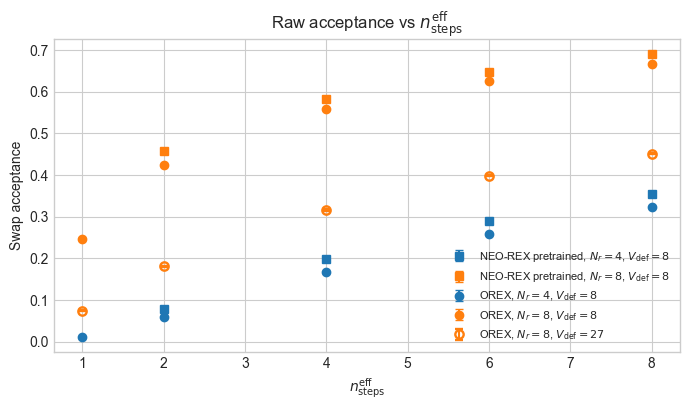

In [43]:
fig, ax = plt.subplots(figsize=(7.0, 4.2))
for algorithm, nrep, vdef, sub in by_algorithm_replica(data):
    style = plot_style(algorithm, nrep, vdef)
    ax.errorbar(
        sub['nsteps_eff'],
        sub['swap_acceptance'],
        yerr=sub['swap_acceptance_sem'],
        marker=style['marker'],
        markerfacecolor=style['markerfacecolor'],
        markeredgewidth=style['markeredgewidth'],
        linestyle='None',
        color=style['color'],
        capsize=3,
        label=fr'{algorithm}, $N_r={nrep}$, $V_{{\rm def}}={vdef}$',
    )
ax.set_xlabel(r'$n_{\mathrm{steps}}^{\rm eff}$')
ax.set_ylabel('Swap acceptance')
ax.set_title(r'Raw acceptance vs $n_{\mathrm{steps}}^{\rm eff}$')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
savefig(fig, 'simple_raw_acceptance_vs_nsteps')
plt.show()

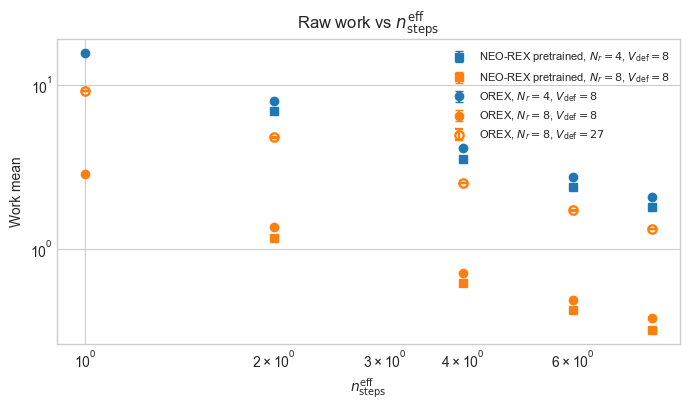

In [44]:
fig, ax = plt.subplots(figsize=(7.0, 4.2))
for algorithm, nrep, vdef, sub in by_algorithm_replica(data):
    style = plot_style(algorithm, nrep, vdef)
    ax.errorbar(
        sub['nsteps_eff'],
        sub['work_mean'],
        yerr=sub['work_sem'],
        marker=style['marker'],
        markerfacecolor=style['markerfacecolor'],
        markeredgewidth=style['markeredgewidth'],
        linestyle='None',
        color=style['color'],
        capsize=3,
        label=fr'{algorithm}, $N_r={nrep}$, $V_{{\rm def}}={vdef}$',
    )
ax.set_xlabel(r'$n_{\mathrm{steps}}^{\rm eff}$')
ax.set_ylabel('Work mean')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_title(r'Raw work vs $n_{\mathrm{steps}}^{\rm eff}$')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
savefig(fig, 'simple_raw_work_vs_nsteps')
plt.show()

## Rescaled x: `$n_{\mathrm{steps}}^{\mathrm{eff}}(N_r-1)^2/V_{\rm def}$`

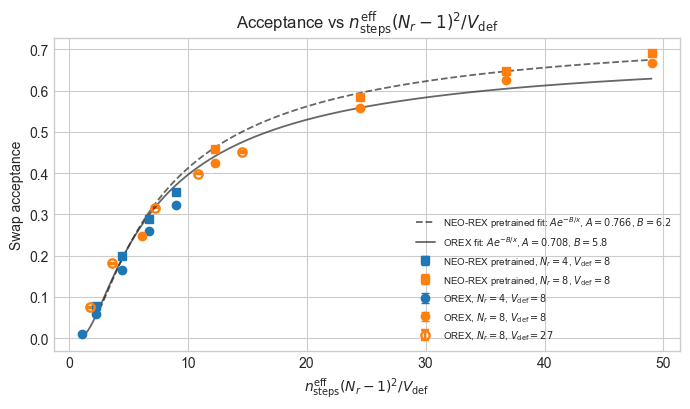

,algorithm,A_acceptance,B_acceptance,A_acceptance_sem,B_acceptance_sem
0,NEO-REX pretrained,0.765513,6.201737,0.001449,0.030885
1,OREX,0.708040,5.818367,0.001225,0.019019


In [45]:
rescaled_data = data.copy()
work_fits = fit_work_by_algorithm(rescaled_data)
acceptance_fits = fit_acceptance_by_algorithm(rescaled_data)
acceptance_fit_residuals = acceptance_residuals(rescaled_data, acceptance_fits)

fig, ax = plt.subplots(figsize=(7.0, 4.2))
for algorithm, nrep, vdef, sub in by_algorithm_replica(rescaled_data):
    style = plot_style(algorithm, nrep, vdef)
    sub = sub.sort_values('x_rescaled')
    ax.errorbar(
        sub['x_rescaled'],
        sub['swap_acceptance'],
        yerr=sub['swap_acceptance_sem'],
        marker=style['marker'],
        markerfacecolor=style['markerfacecolor'],
        markeredgewidth=style['markeredgewidth'],
        linestyle='None',
        color=style['color'],
        capsize=3,
        label=fr'{algorithm}, $N_r={nrep}$, $V_{{\rm def}}={vdef}$',
    )
for _, row in acceptance_fits.iterrows():
    sub = rescaled_data[rescaled_data['algorithm'] == row['algorithm']]
    xs = np.geomspace(sub['x_rescaled'].min(), sub['x_rescaled'].max(), 240)
    line_style = fit_line_style(row['algorithm'])
    ax.plot(
        xs,
        acceptance_model(xs, row['A_acceptance'], row['B_acceptance']),
        color=line_style['color'],
        linestyle=line_style['linestyle'],
        linewidth=1.3,
        alpha=0.7,
        label=fr"{row['algorithm']} fit: $A e^{{-B/x}}$, $A={row['A_acceptance']:.3f}$, $B={row['B_acceptance']:.1f}$",
    )
ax.set_xlabel(r'$n_{\mathrm{steps}}^{\mathrm{eff}}(N_r-1)^2/V_{\rm def}$')
ax.set_ylabel('Swap acceptance')
ax.set_title(r'Acceptance vs $n_{\mathrm{steps}}^{\mathrm{eff}}(N_r-1)^2/V_{\rm def}$')
ax.legend(frameon=False, fontsize=7)
fig.tight_layout()
savefig(fig, 'simple_rescaled_acceptance_vs_nsteps_Nrminus1sq')
plt.show()

acceptance_fits

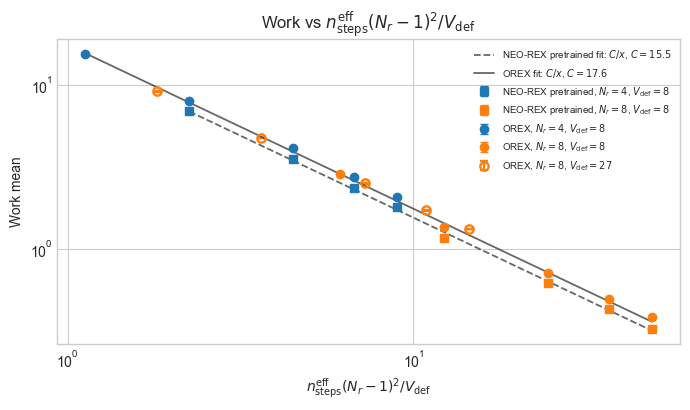

,algorithm,C_work,C_work_sem
0,NEO-REX pretrained,15.539743,0.026783
1,OREX,17.615468,0.016213


In [46]:
fig, ax = plt.subplots(figsize=(7.0, 4.2))
for algorithm, nrep, vdef, sub in by_algorithm_replica(rescaled_data):
    style = plot_style(algorithm, nrep, vdef)
    sub = sub.sort_values('x_rescaled')
    ax.errorbar(
        sub['x_rescaled'],
        sub['work_mean'],
        yerr=sub['work_sem'],
        marker=style['marker'],
        markerfacecolor=style['markerfacecolor'],
        markeredgewidth=style['markeredgewidth'],
        linestyle='None',
        color=style['color'],
        capsize=3,
        label=fr'{algorithm}, $N_r={nrep}$, $V_{{\rm def}}={vdef}$',
    )
for _, row in work_fits.iterrows():
    sub = rescaled_data[rescaled_data['algorithm'] == row['algorithm']]
    xs = np.geomspace(sub['x_rescaled'].min(), sub['x_rescaled'].max(), 240)
    line_style = fit_line_style(row['algorithm'])
    ax.plot(
        xs,
        work_model(xs, row['C_work']),
        color=line_style['color'],
        linestyle=line_style['linestyle'],
        linewidth=1.3,
        alpha=0.7,
        label=fr"{row['algorithm']} fit: $C/x$, $C={row['C_work']:.1f}$",
    )
ax.set_xlabel(r'$n_{\mathrm{steps}}^{\mathrm{eff}}(N_r-1)^2/V_{\rm def}$')
ax.set_ylabel('Work mean')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_title(r'Work vs $n_{\mathrm{steps}}^{\mathrm{eff}}(N_r-1)^2/V_{\rm def}$')
ax.legend(frameon=False, fontsize=7)
fig.tight_layout()
savefig(fig, 'simple_rescaled_work_vs_nsteps_Nrminus1sq')
plt.show()

work_fits

## Rescaled x: `$n_{\mathrm{steps}}^{\mathrm{eff}}N_r/V_{\rm def}$`

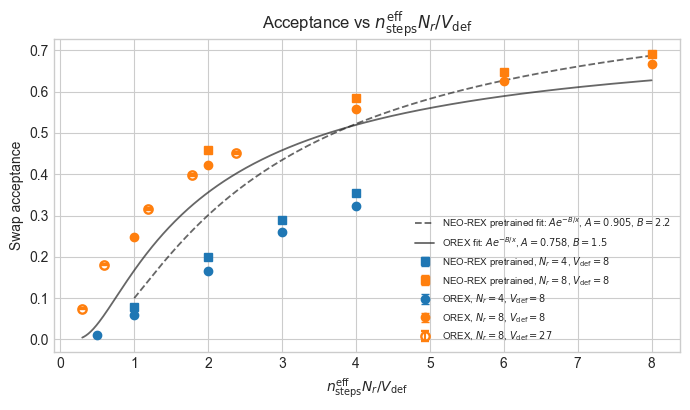

,algorithm,A_acceptance,B_acceptance,A_acceptance_sem,B_acceptance_sem
0,NEO-REX pretrained,0.904665,2.200873,0.002294,0.009842
1,OREX,0.757601,1.510009,0.001417,0.004291


In [47]:
nr_rescaled_data = data.copy()
nr_rescaled_data['x_rescaled'] = nr_rescaled_data['nsteps_eff'] * nr_rescaled_data['nreplicas'] / nr_rescaled_data['defect_volume']
nr_work_fits = fit_work_by_algorithm(nr_rescaled_data)
nr_acceptance_fits = fit_acceptance_by_algorithm(nr_rescaled_data)
nr_acceptance_fit_residuals = acceptance_residuals(nr_rescaled_data, nr_acceptance_fits)
nr_fit_summary = nr_work_fits.merge(nr_acceptance_fits, on='algorithm', how='outer')

fig, ax = plt.subplots(figsize=(7.0, 4.2))
for algorithm, nrep, vdef, sub in by_algorithm_replica(nr_rescaled_data):
    style = plot_style(algorithm, nrep, vdef)
    sub = sub.sort_values('x_rescaled')
    ax.errorbar(
        sub['x_rescaled'],
        sub['swap_acceptance'],
        yerr=sub['swap_acceptance_sem'],
        marker=style['marker'],
        markerfacecolor=style['markerfacecolor'],
        markeredgewidth=style['markeredgewidth'],
        linestyle='None',
        color=style['color'],
        capsize=3,
        label=fr'{algorithm}, $N_r={nrep}$, $V_{{\rm def}}={vdef}$',
    )
for _, row in nr_acceptance_fits.iterrows():
    sub = nr_rescaled_data[nr_rescaled_data['algorithm'] == row['algorithm']]
    xs = np.geomspace(sub['x_rescaled'].min(), sub['x_rescaled'].max(), 240)
    line_style = fit_line_style(row['algorithm'])
    ax.plot(
        xs,
        acceptance_model(xs, row['A_acceptance'], row['B_acceptance']),
        color=line_style['color'],
        linestyle=line_style['linestyle'],
        linewidth=1.3,
        alpha=0.7,
        label=fr"{row['algorithm']} fit: $A e^{{-B/x}}$, $A={row['A_acceptance']:.3f}$, $B={row['B_acceptance']:.1f}$",
    )
ax.set_xlabel(r'$n_{\mathrm{steps}}^{\mathrm{eff}}N_r/V_{\rm def}$')
ax.set_ylabel('Swap acceptance')
ax.set_title(r'Acceptance vs $n_{\mathrm{steps}}^{\mathrm{eff}}N_r/V_{\rm def}$')
ax.legend(frameon=False, fontsize=7)
fig.tight_layout()
savefig(fig, 'simple_rescaled_acceptance_vs_nsteps_Nr')
plt.show()

nr_acceptance_fits

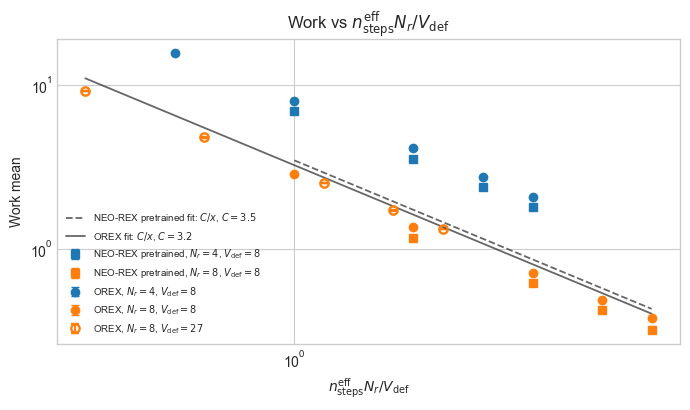

,algorithm,C_work,C_work_sem
0,NEO-REX pretrained,3.461941,0.006812
1,OREX,3.235271,0.003225


In [48]:
fig, ax = plt.subplots(figsize=(7.0, 4.2))
for algorithm, nrep, vdef, sub in by_algorithm_replica(nr_rescaled_data):
    style = plot_style(algorithm, nrep, vdef)
    sub = sub.sort_values('x_rescaled')
    ax.errorbar(
        sub['x_rescaled'],
        sub['work_mean'],
        yerr=sub['work_sem'],
        marker=style['marker'],
        markerfacecolor=style['markerfacecolor'],
        markeredgewidth=style['markeredgewidth'],
        linestyle='None',
        color=style['color'],
        capsize=3,
        label=fr'{algorithm}, $N_r={nrep}$, $V_{{\rm def}}={vdef}$',
    )
for _, row in nr_work_fits.iterrows():
    sub = nr_rescaled_data[nr_rescaled_data['algorithm'] == row['algorithm']]
    xs = np.geomspace(sub['x_rescaled'].min(), sub['x_rescaled'].max(), 240)
    line_style = fit_line_style(row['algorithm'])
    ax.plot(
        xs,
        work_model(xs, row['C_work']),
        color=line_style['color'],
        linestyle=line_style['linestyle'],
        linewidth=1.3,
        alpha=0.7,
        label=fr"{row['algorithm']} fit: $C/x$, $C={row['C_work']:.1f}$",
    )
ax.set_xlabel(r'$n_{\mathrm{steps}}^{\mathrm{eff}}N_r/V_{\rm def}$')
ax.set_ylabel('Work mean')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_title(r'Work vs $n_{\mathrm{steps}}^{\mathrm{eff}}N_r/V_{\rm def}$')
ax.legend(frameon=False, fontsize=7)
fig.tight_layout()
savefig(fig, 'simple_rescaled_work_vs_nsteps_Nr')
plt.show()

nr_work_fits

## Acceptance erfc fit

Fit alternativo sull'asse principale `$x=n_{\mathrm{steps}}^{\mathrm{eff}}(N_r-1)^2/V_{\rm def}$`:

`$acc = A\,\mathrm{erfc}(B/\sqrt{x})$`.

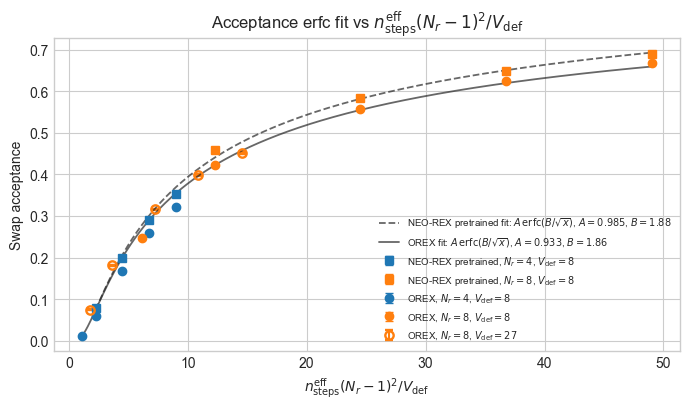

,algorithm,A_erfc_acceptance,B_erfc_acceptance,A_erfc_acceptance_sem,B_erfc_acceptance_sem
0,NEO-REX pretrained,0.984710,1.882407,0.002343,0.005817
1,OREX,0.932973,1.861933,0.001859,0.003568


In [49]:
erfc_rescaled_data = data.copy()
erfc_rescaled_data['x_rescaled'] = erfc_rescaled_data['nsteps_eff'] * (erfc_rescaled_data['nreplicas'] - 1.0) ** 2 / erfc_rescaled_data['defect_volume']
erfc_acceptance_fits = fit_acceptance_erfc_by_algorithm(erfc_rescaled_data)
erfc_acceptance_fit_residuals = acceptance_erfc_residuals(erfc_rescaled_data, erfc_acceptance_fits)

fig, ax = plt.subplots(figsize=(7.0, 4.2))
for algorithm, nrep, vdef, sub in by_algorithm_replica(erfc_rescaled_data):
    style = plot_style(algorithm, nrep, vdef)
    sub = sub.sort_values('x_rescaled')
    ax.errorbar(
        sub['x_rescaled'],
        sub['swap_acceptance'],
        yerr=sub['swap_acceptance_sem'],
        marker=style['marker'],
        markerfacecolor=style['markerfacecolor'],
        markeredgewidth=style['markeredgewidth'],
        linestyle='None',
        color=style['color'],
        capsize=3,
        label=fr'{algorithm}, $N_r={nrep}$, $V_{{\rm def}}={vdef}$',
    )
for _, row in erfc_acceptance_fits.iterrows():
    sub = erfc_rescaled_data[erfc_rescaled_data['algorithm'] == row['algorithm']]
    xs = np.geomspace(sub['x_rescaled'].min(), sub['x_rescaled'].max(), 240)
    line_style = fit_line_style(row['algorithm'])
    ax.plot(
        xs,
        acceptance_erfc_model(xs, row['A_erfc_acceptance'], row['B_erfc_acceptance']),
        color=line_style['color'],
        linestyle=line_style['linestyle'],
        linewidth=1.3,
        alpha=0.7,
        label=fr"{row['algorithm']} fit: $A\,\mathrm{{erfc}}(B/\sqrt{{x}})$, $A={row['A_erfc_acceptance']:.3f}$, $B={row['B_erfc_acceptance']:.2f}$",
    )
ax.set_xlabel(r'$n_{\mathrm{steps}}^{\mathrm{eff}}(N_r-1)^2/V_{\rm def}$')
ax.set_ylabel('Swap acceptance')
ax.set_title(r'Acceptance erfc fit vs $n_{\mathrm{steps}}^{\mathrm{eff}}(N_r-1)^2/V_{\rm def}$')
ax.legend(frameon=False, fontsize=7)
fig.tight_layout()
savefig(fig, 'simple_rescaled_acceptance_erfc_vs_nsteps_Nrminus1sq')
plt.show()

erfc_acceptance_fits

## Rescaled x: `$\sqrt{n_{\mathrm{steps}}^{\mathrm{eff}}}(N_r-1)/\sqrt{V_{\rm def}}$`

Qui usiamo `$x=\sqrt{n_{\mathrm{steps}}^{\mathrm{eff}}}(N_r-1)/\sqrt{V_{\rm def}}$`.
Per coerenza con `$W\sim 1/[n_{\mathrm{steps}}^{\mathrm{eff}}(N_r-1)^2/V_{\rm def}]$`, il fit guida del lavoro e' `$W=C/x^2$`.
Per l'accettanza usiamo `$acc=A\,\mathrm{erfc}(B/x)$`.

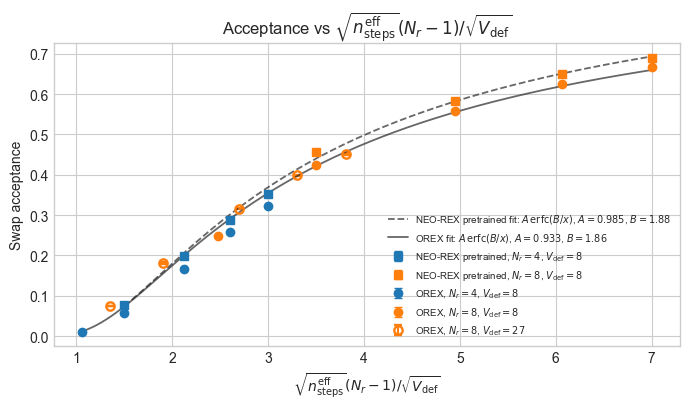

,algorithm,A_sqrt_erfc_acceptance,B_sqrt_erfc_acceptance,A_sqrt_erfc_acceptance_sem,B_sqrt_erfc_acceptance_sem
0,NEO-REX pretrained,0.984710,1.882407,0.002343,0.005817
1,OREX,0.932973,1.861933,0.001859,0.003568


In [50]:
sqrt_rescaled_data = data.copy()
sqrt_rescaled_data['x_sqrt'] = np.sqrt(sqrt_rescaled_data['nsteps_eff']) * (sqrt_rescaled_data['nreplicas'] - 1.0) / np.sqrt(sqrt_rescaled_data['defect_volume'])
sqrt_work_fits = fit_sqrt_work_by_algorithm(sqrt_rescaled_data)
sqrt_acceptance_fits = fit_sqrt_acceptance_erfc_by_algorithm(sqrt_rescaled_data)
sqrt_acceptance_fit_residuals = sqrt_acceptance_erfc_residuals(sqrt_rescaled_data, sqrt_acceptance_fits)
sqrt_fit_summary = sqrt_work_fits.merge(sqrt_acceptance_fits, on='algorithm', how='outer')

fig, ax = plt.subplots(figsize=(7.0, 4.2))
for algorithm, nrep, vdef, sub in by_algorithm_replica(sqrt_rescaled_data):
    style = plot_style(algorithm, nrep, vdef)
    sub = sub.sort_values('x_sqrt')
    ax.errorbar(
        sub['x_sqrt'],
        sub['swap_acceptance'],
        yerr=sub['swap_acceptance_sem'],
        marker=style['marker'],
        markerfacecolor=style['markerfacecolor'],
        markeredgewidth=style['markeredgewidth'],
        linestyle='None',
        color=style['color'],
        capsize=3,
        label=fr'{algorithm}, $N_r={nrep}$, $V_{{\rm def}}={vdef}$',
    )
for _, row in sqrt_acceptance_fits.iterrows():
    sub = sqrt_rescaled_data[sqrt_rescaled_data['algorithm'] == row['algorithm']]
    xs = np.linspace(sub['x_sqrt'].min(), sub['x_sqrt'].max(), 240)
    line_style = fit_line_style(row['algorithm'])
    ax.plot(
        xs,
        sqrt_acceptance_erfc_model(xs, row['A_sqrt_erfc_acceptance'], row['B_sqrt_erfc_acceptance']),
        color=line_style['color'],
        linestyle=line_style['linestyle'],
        linewidth=1.3,
        alpha=0.7,
        label=fr"{row['algorithm']} fit: $A\,\mathrm{{erfc}}(B/x)$, $A={row['A_sqrt_erfc_acceptance']:.3f}$, $B={row['B_sqrt_erfc_acceptance']:.2f}$",
    )
ax.set_xlabel(r'$\sqrt{n_{\mathrm{steps}}^{\mathrm{eff}}}(N_r-1)/\sqrt{V_{\rm def}}$')
ax.set_ylabel('Swap acceptance')
ax.set_title(r'Acceptance vs $\sqrt{n_{\mathrm{steps}}^{\mathrm{eff}}}(N_r-1)/\sqrt{V_{\rm def}}$')
ax.legend(frameon=False, fontsize=7)
fig.tight_layout()
savefig(fig, 'simple_rescaled_acceptance_vs_sqrt_nsteps_Nrminus1')
plt.show()

sqrt_acceptance_fits

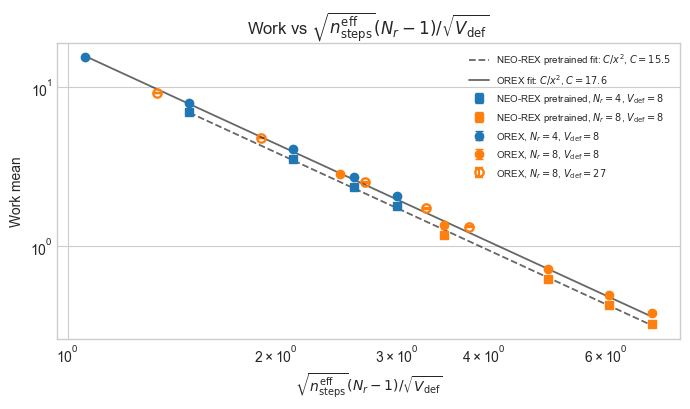

,algorithm,C_sqrt_work,C_sqrt_work_sem
0,NEO-REX pretrained,15.539743,0.026783
1,OREX,17.615468,0.016213


In [51]:
fig, ax = plt.subplots(figsize=(7.0, 4.2))
for algorithm, nrep, vdef, sub in by_algorithm_replica(sqrt_rescaled_data):
    style = plot_style(algorithm, nrep, vdef)
    sub = sub.sort_values('x_sqrt')
    ax.errorbar(
        sub['x_sqrt'],
        sub['work_mean'],
        yerr=sub['work_sem'],
        marker=style['marker'],
        markerfacecolor=style['markerfacecolor'],
        markeredgewidth=style['markeredgewidth'],
        linestyle='None',
        color=style['color'],
        capsize=3,
        label=fr'{algorithm}, $N_r={nrep}$, $V_{{\rm def}}={vdef}$',
    )
for _, row in sqrt_work_fits.iterrows():
    sub = sqrt_rescaled_data[sqrt_rescaled_data['algorithm'] == row['algorithm']]
    xs = np.geomspace(sub['x_sqrt'].min(), sub['x_sqrt'].max(), 240)
    line_style = fit_line_style(row['algorithm'])
    ax.plot(
        xs,
        sqrt_work_model(xs, row['C_sqrt_work']),
        color=line_style['color'],
        linestyle=line_style['linestyle'],
        linewidth=1.3,
        alpha=0.7,
        label=fr"{row['algorithm']} fit: $C/x^2$, $C={row['C_sqrt_work']:.1f}$",
    )
ax.set_xlabel(r'$\sqrt{n_{\mathrm{steps}}^{\mathrm{eff}}}(N_r-1)/\sqrt{V_{\rm def}}$')
ax.set_ylabel('Work mean')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_title(r'Work vs $\sqrt{n_{\mathrm{steps}}^{\mathrm{eff}}}(N_r-1)/\sqrt{V_{\rm def}}$')
ax.legend(frameon=False, fontsize=7)
fig.tight_layout()
savefig(fig, 'simple_rescaled_work_vs_sqrt_nsteps_Nrminus1')
plt.show()

sqrt_work_fits

## Test scaling with `$N_r^2$` instead of `$(N_r-1)^2$`

Test alternativo:

`$x_N = n_{\mathrm{steps}}^{\mathrm{eff}} N_r^2 / V_{\rm def}$`, con fit lavoro `$W=C/x_N$`.

Per l'accettanza usiamo la variabile in radice `$z_N = \sqrt{n_{\mathrm{steps}}^{\mathrm{eff}}}\,N_r/\sqrt{V_{\rm def}}$` e fit `$acc=A\,\mathrm{erfc}(B/z_N)$`.

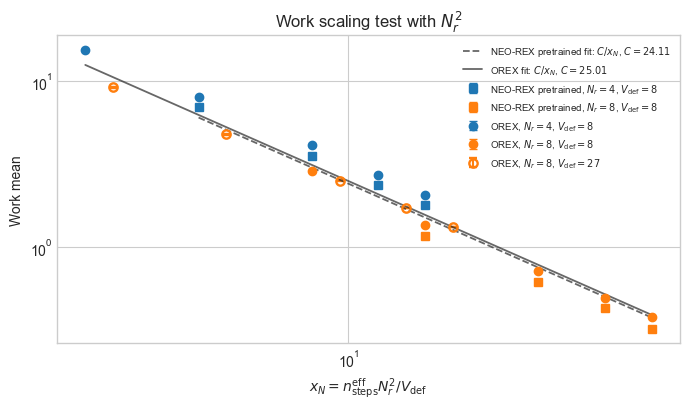

,algorithm,C_work,C_work_sem
0,NEO-REX pretrained,24.113577,0.042198
1,OREX,25.014397,0.023295


In [52]:
nr2_rescaled_data = data.copy()
nr2_rescaled_data['x_rescaled'] = nr2_rescaled_data['nsteps_eff'] * nr2_rescaled_data['nreplicas'] ** 2 / nr2_rescaled_data['defect_volume']
nr2_rescaled_data['x_sqrt'] = np.sqrt(nr2_rescaled_data['x_rescaled'])
nr2_work_fits = fit_work_by_algorithm(nr2_rescaled_data)
nr2_acceptance_fits = fit_sqrt_acceptance_erfc_by_algorithm(nr2_rescaled_data)
nr2_acceptance_fit_residuals = sqrt_acceptance_erfc_residuals(nr2_rescaled_data, nr2_acceptance_fits)
nr2_fit_summary = nr2_work_fits.merge(nr2_acceptance_fits, on='algorithm', how='outer')

fig, ax = plt.subplots(figsize=(7.0, 4.2))
for algorithm, nrep, vdef, sub in by_algorithm_replica(nr2_rescaled_data):
    style = plot_style(algorithm, nrep, vdef)
    sub = sub.sort_values('x_rescaled')
    ax.errorbar(
        sub['x_rescaled'],
        sub['work_mean'],
        yerr=sub['work_sem'],
        marker=style['marker'],
        markerfacecolor=style['markerfacecolor'],
        markeredgewidth=style['markeredgewidth'],
        linestyle='None',
        color=style['color'],
        capsize=3,
        label=fr'{algorithm}, $N_r={nrep}$, $V_{{\rm def}}={vdef}$',
    )
for _, row in nr2_work_fits.iterrows():
    sub = nr2_rescaled_data[nr2_rescaled_data['algorithm'] == row['algorithm']]
    xs = np.geomspace(sub['x_rescaled'].min(), sub['x_rescaled'].max(), 240)
    line_style = fit_line_style(row['algorithm'])
    ax.plot(
        xs,
        work_model(xs, row['C_work']),
        color=line_style['color'],
        linestyle=line_style['linestyle'],
        linewidth=1.3,
        alpha=0.7,
        label=fr"{row['algorithm']} fit: $C/x_N$, $C={row['C_work']:.2f}$",
    )
ax.set_xlabel(r'$x_N=n_{\mathrm{steps}}^{\mathrm{eff}}N_r^2/V_{\mathrm{def}}$')
ax.set_ylabel('Work mean')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_title(r'Work scaling test with $N_r^2$')
ax.legend(frameon=False, fontsize=7)
fig.tight_layout()
savefig(fig, 'simple_rescaled_work_vs_nsteps_Nrsq_over_Vdef')
plt.show()

nr2_work_fits

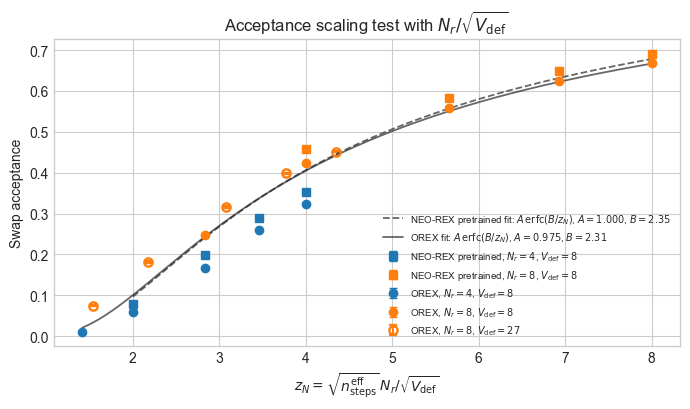

,algorithm,A_sqrt_erfc_acceptance,B_sqrt_erfc_acceptance,A_sqrt_erfc_acceptance_sem,B_sqrt_erfc_acceptance_sem
0,NEO-REX pretrained,1.000000,2.349396,0.002585,0.007255
1,OREX,0.975346,2.306409,0.001987,0.004228


In [53]:
fig, ax = plt.subplots(figsize=(7.0, 4.2))
for algorithm, nrep, vdef, sub in by_algorithm_replica(nr2_rescaled_data):
    style = plot_style(algorithm, nrep, vdef)
    sub = sub.sort_values('x_sqrt')
    ax.errorbar(
        sub['x_sqrt'],
        sub['swap_acceptance'],
        yerr=sub['swap_acceptance_sem'],
        marker=style['marker'],
        markerfacecolor=style['markerfacecolor'],
        markeredgewidth=style['markeredgewidth'],
        linestyle='None',
        color=style['color'],
        capsize=3,
        label=fr'{algorithm}, $N_r={nrep}$, $V_{{\rm def}}={vdef}$',
    )
for _, row in nr2_acceptance_fits.iterrows():
    sub = nr2_rescaled_data[nr2_rescaled_data['algorithm'] == row['algorithm']]
    xs = np.linspace(sub['x_sqrt'].min(), sub['x_sqrt'].max(), 240)
    line_style = fit_line_style(row['algorithm'])
    ax.plot(
        xs,
        sqrt_acceptance_erfc_model(xs, row['A_sqrt_erfc_acceptance'], row['B_sqrt_erfc_acceptance']),
        color=line_style['color'],
        linestyle=line_style['linestyle'],
        linewidth=1.3,
        alpha=0.7,
        label=fr"{row['algorithm']} fit: $A\,\mathrm{{erfc}}(B/z_N)$, $A={row['A_sqrt_erfc_acceptance']:.3f}$, $B={row['B_sqrt_erfc_acceptance']:.2f}$",
    )
ax.set_xlabel(r'$z_N=\sqrt{n_{\mathrm{steps}}^{\mathrm{eff}}}\,N_r/\sqrt{V_{\mathrm{def}}}$')
ax.set_ylabel('Swap acceptance')
ax.set_title(r'Acceptance scaling test with $N_r/\sqrt{V_{\mathrm{def}}}$')
ax.legend(frameon=False, fontsize=7)
fig.tight_layout()
savefig(fig, 'simple_rescaled_acceptance_vs_sqrt_nsteps_Nr_over_sqrtVdef')
plt.show()

nr2_acceptance_fits

## Inverse-erfc acceptance diagnostic

Test senza nuovi parametri fisici: con `$V_{\rm def}=d_{\rm def}^3$` e

`$z=\sqrt{n_{\rm steps}^{\rm eff}}(N_r-1)/\sqrt{V_{\rm def}}$`,

se `$acc=\mathrm{erfc}(B/z)$`, allora

`$\mathrm{erfc}^{-1}(acc)=B/z$`.

Quindi plottiamo `$\mathrm{erfc}^{-1}(acc)$` contro `$1/z$`.

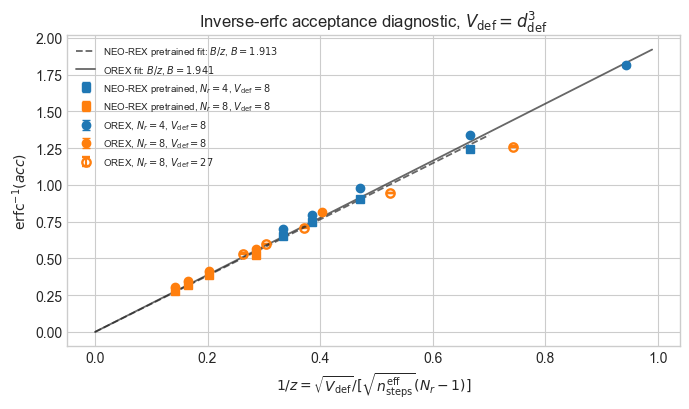

,algorithm,B_erfcinv,B_erfcinv_sem,erfcinv_rmse
0,NEO-REX pretrained,1.912866,0.003096,0.016116
1,OREX,1.940587,0.001936,0.059523


In [54]:
erfcinv_data = data.copy()
erfcinv_data['z_acceptance'] = np.sqrt(erfcinv_data['nsteps_eff']) * (erfcinv_data['nreplicas'] - 1.0) / np.sqrt(erfcinv_data['defect_volume'])
erfcinv_data['inv_z'] = 1.0 / erfcinv_data['z_acceptance']
erfcinv_data['erfcinv_acceptance'] = erfcinv(np.clip(erfcinv_data['swap_acceptance'], 1e-12, 1.0 - 1e-12))
erfcinv_fits = fit_erfcinv_slope_by_algorithm(erfcinv_data)

fig, ax = plt.subplots(figsize=(7.0, 4.2))
for algorithm, nrep, vdef, sub in by_algorithm_replica(erfcinv_data):
    style = plot_style(algorithm, nrep, vdef)
    sub = sub.sort_values('inv_z')
    yerr = 0.5 * np.sqrt(np.pi) * np.exp(sub['erfcinv_acceptance'] ** 2) * sub['swap_acceptance_sem']
    ax.errorbar(
        sub['inv_z'],
        sub['erfcinv_acceptance'],
        yerr=yerr,
        marker=style['marker'],
        markerfacecolor=style['markerfacecolor'],
        markeredgewidth=style['markeredgewidth'],
        linestyle='None',
        color=style['color'],
        capsize=3,
        label=fr'{algorithm}, $N_r={nrep}$, $V_{{\mathrm{{def}}}}={vdef}$',
    )
for _, row in erfcinv_fits.iterrows():
    sub = erfcinv_data[erfcinv_data['algorithm'] == row['algorithm']]
    xs = np.linspace(0.0, sub['inv_z'].max() * 1.05, 240)
    line_style = fit_line_style(row['algorithm'])
    ax.plot(
        xs,
        erfcinv_acceptance_model(xs, row['B_erfcinv']),
        color=line_style['color'],
        linestyle=line_style['linestyle'],
        linewidth=1.3,
        alpha=0.7,
        label=fr"{row['algorithm']} fit: $B/z$, $B={row['B_erfcinv']:.3f}$",
    )
ax.set_xlabel(r'$1/z=\sqrt{V_{\mathrm{def}}}/[\sqrt{n_{\mathrm{steps}}^{\mathrm{eff}}}(N_r-1)]$')
ax.set_ylabel(r'$\mathrm{erfc}^{-1}(acc)$')
ax.set_title(r'Inverse-erfc acceptance diagnostic, $V_{\mathrm{def}}=d_{\mathrm{def}}^3$')
ax.legend(frameon=False, fontsize=7)
fig.tight_layout()
savefig(fig, 'simple_acceptance_inverse_erfc_vs_inv_z_Vdef')
plt.show()

erfcinv_fits

## Plaquette-count acceptance diagnostic

Qui non fittiamo nuove potenze. Usiamo il numero geometrico di plaquette temporali-spaziali il cui termine contiene almeno un link temporale del difetto.

Per un difetto cubico spaziale di lato `$d$` in 4D:

`$N_{\rm plaq,def}=3 d^2(d+1)$`.

Quindi testiamo:

`$z_{\rm plaq}=\sqrt{n_{\rm steps}^{\rm eff}}(N_r-1)/\sqrt{N_{\rm plaq,def}}$`.

Se `$acc=\mathrm{erfc}(B/z_{\rm plaq})$`, allora `$\mathrm{erfc}^{-1}(acc)=B/z_{\rm plaq}$`.

In [55]:
plaq_data = data.copy()
plaq_data['n_defect_plaquettes'] = 3.0 * plaq_data['defect_size'] ** 2 * (plaq_data['defect_size'] + 1.0)
plaq_data['z_plaq'] = np.sqrt(plaq_data['nsteps_eff']) * (plaq_data['nreplicas'] - 1.0) / np.sqrt(plaq_data['n_defect_plaquettes'])
plaq_data['inv_z_plaq'] = 1.0 / plaq_data['z_plaq']
plaq_data['erfcinv_acceptance'] = erfcinv(np.clip(plaq_data['swap_acceptance'], 1e-12, 1.0 - 1e-12))

# Reuse the same erfc fit machinery by replacing x_sqrt with z_plaq.
plaq_fit_data = plaq_data.copy()
plaq_fit_data['x_sqrt'] = plaq_fit_data['z_plaq']
plaq_acceptance_fits = fit_sqrt_acceptance_erfc_by_algorithm(plaq_fit_data)
plaq_acceptance_fit_residuals = sqrt_acceptance_erfc_residuals(plaq_fit_data, plaq_acceptance_fits)
plaq_erfcinv_data = plaq_data.copy()
plaq_erfcinv_data['inv_z'] = plaq_erfcinv_data['inv_z_plaq']
plaq_erfcinv_fits = fit_erfcinv_slope_by_algorithm(plaq_erfcinv_data)

plaq_data[['algorithm', 'defect_size', 'defect_volume', 'n_defect_plaquettes', 'nreplicas', 'nsteps', 'z_plaq', 'inv_z_plaq', 'swap_acceptance', 'erfcinv_acceptance']]

,algorithm,defect_size,defect_volume,n_defect_plaquettes,nreplicas,nsteps,z_plaq,inv_z_plaq,swap_acceptance,erfcinv_acceptance
0,OREX,2,8,36.0,4,0,0.500000,2.000000,0.010286,1.814481
1,OREX,2,8,36.0,4,2,0.707107,1.414214,0.058750,1.336474
2,OREX,2,8,36.0,4,4,1.000000,1.000000,0.166354,0.978646
3,OREX,2,8,36.0,4,6,1.224745,0.816497,0.259323,0.797611
4,OREX,2,8,36.0,4,8,1.414214,0.707107,0.322604,0.699414
5,OREX,2,8,36.0,8,0,1.166667,0.857143,0.247355,0.817980
6,OREX,2,8,36.0,8,2,1.649916,0.606092,0.423315,0.566169
7,OREX,2,8,36.0,8,4,2.333333,0.428571,0.557723,0.414525
8,OREX,2,8,36.0,8,6,2.857738,0.349927,0.625156,0.345461
9,OREX,2,8,36.0,8,8,3.299832,0.303046,0.667913,0.303359


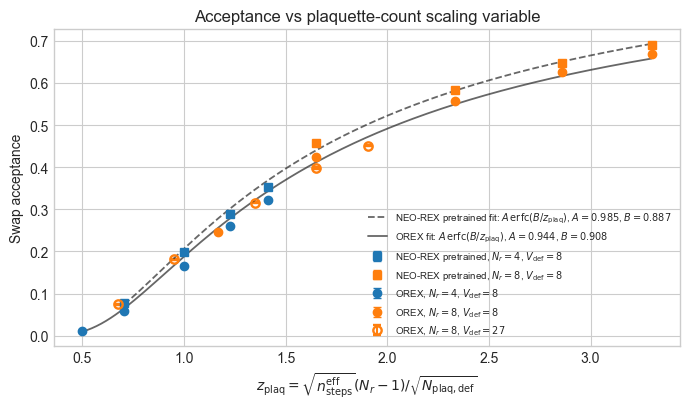

,algorithm,A_sqrt_erfc_acceptance,B_sqrt_erfc_acceptance,A_sqrt_erfc_acceptance_sem,B_sqrt_erfc_acceptance_sem
0,NEO-REX pretrained,0.984710,0.887375,0.002343,0.002742
1,OREX,0.943888,0.908258,0.001914,0.001754


In [56]:
fig, ax = plt.subplots(figsize=(7.0, 4.2))
for algorithm, nrep, vdef, sub in by_algorithm_replica(plaq_data):
    style = plot_style(algorithm, nrep, vdef)
    sub = sub.sort_values('z_plaq')
    ax.errorbar(
        sub['z_plaq'],
        sub['swap_acceptance'],
        yerr=sub['swap_acceptance_sem'],
        marker=style['marker'],
        markerfacecolor=style['markerfacecolor'],
        markeredgewidth=style['markeredgewidth'],
        linestyle='None',
        color=style['color'],
        capsize=3,
        label=fr'{algorithm}, $N_r={nrep}$, $V_{{\mathrm{{def}}}}={vdef}$',
    )
for _, row in plaq_acceptance_fits.iterrows():
    sub = plaq_fit_data[plaq_fit_data['algorithm'] == row['algorithm']]
    xs = np.linspace(sub['x_sqrt'].min(), sub['x_sqrt'].max(), 240)
    line_style = fit_line_style(row['algorithm'])
    ax.plot(
        xs,
        sqrt_acceptance_erfc_model(xs, row['A_sqrt_erfc_acceptance'], row['B_sqrt_erfc_acceptance']),
        color=line_style['color'],
        linestyle=line_style['linestyle'],
        linewidth=1.3,
        alpha=0.7,
        label=fr"{row['algorithm']} fit: $A\,\mathrm{{erfc}}(B/z_{{\rm plaq}})$, $A={row['A_sqrt_erfc_acceptance']:.3f}$, $B={row['B_sqrt_erfc_acceptance']:.3f}$",
    )
ax.set_xlabel(r'$z_{\mathrm{plaq}}=\sqrt{n_{\mathrm{steps}}^{\mathrm{eff}}}(N_r-1)/\sqrt{N_{\mathrm{plaq,def}}}$')
ax.set_ylabel('Swap acceptance')
ax.set_title(r'Acceptance vs plaquette-count scaling variable')
ax.legend(frameon=False, fontsize=7)
fig.tight_layout()
savefig(fig, 'simple_acceptance_vs_z_plaq_def')
plt.show()

plaq_acceptance_fits

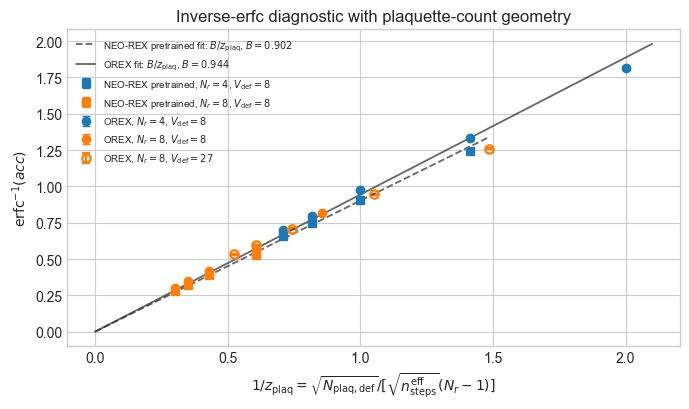

,algorithm,B_erfcinv,B_erfcinv_sem,erfcinv_rmse
0,NEO-REX pretrained,0.901734,0.001459,0.016116
1,OREX,0.943548,0.000941,0.046834


In [57]:
fig, ax = plt.subplots(figsize=(7.0, 4.2))
for algorithm, nrep, vdef, sub in by_algorithm_replica(plaq_data):
    style = plot_style(algorithm, nrep, vdef)
    sub = sub.sort_values('inv_z_plaq')
    yerr = 0.5 * np.sqrt(np.pi) * np.exp(sub['erfcinv_acceptance'] ** 2) * sub['swap_acceptance_sem']
    ax.errorbar(
        sub['inv_z_plaq'],
        sub['erfcinv_acceptance'],
        yerr=yerr,
        marker=style['marker'],
        markerfacecolor=style['markerfacecolor'],
        markeredgewidth=style['markeredgewidth'],
        linestyle='None',
        color=style['color'],
        capsize=3,
        label=fr'{algorithm}, $N_r={nrep}$, $V_{{\mathrm{{def}}}}={vdef}$',
    )
for _, row in plaq_erfcinv_fits.iterrows():
    sub = plaq_data[plaq_data['algorithm'] == row['algorithm']]
    xs = np.linspace(0.0, sub['inv_z_plaq'].max() * 1.05, 240)
    line_style = fit_line_style(row['algorithm'])
    ax.plot(
        xs,
        erfcinv_acceptance_model(xs, row['B_erfcinv']),
        color=line_style['color'],
        linestyle=line_style['linestyle'],
        linewidth=1.3,
        alpha=0.7,
        label=fr"{row['algorithm']} fit: $B/z_{{\rm plaq}}$, $B={row['B_erfcinv']:.3f}$",
    )
ax.set_xlabel(r'$1/z_{\mathrm{plaq}}=\sqrt{N_{\mathrm{plaq,def}}}/[\sqrt{n_{\mathrm{steps}}^{\mathrm{eff}}}(N_r-1)]$')
ax.set_ylabel(r'$\mathrm{erfc}^{-1}(acc)$')
ax.set_title(r'Inverse-erfc diagnostic with plaquette-count geometry')
ax.legend(frameon=False, fontsize=7)
fig.tight_layout()
savefig(fig, 'simple_acceptance_inverse_erfc_vs_inv_z_plaq_def')
plt.show()

plaq_erfcinv_fits

## Plaquette-count work diagnostic

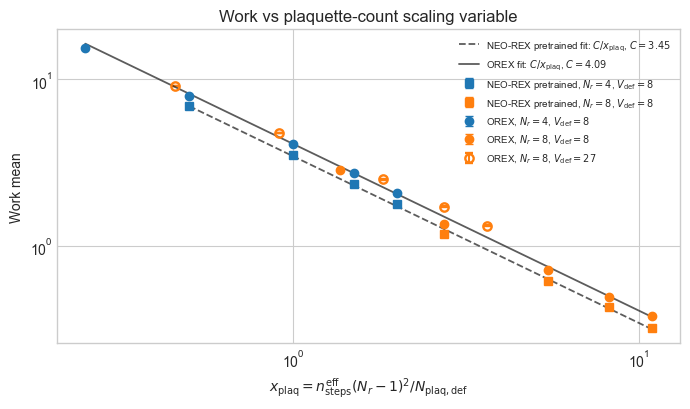

,algorithm,C_work,C_work_sem,work_rmse,work_weighted_rmse
0,NEO-REX pretrained,3.453276,0.005952,0.056819,0.034896
1,OREX,4.094592,0.003773,0.277705,0.113087


In [58]:

plaq_work_data = plaq_data.copy() if 'plaq_data' in globals() else data.copy()
if 'n_defect_plaquettes' not in plaq_work_data.columns:
    plaq_work_data['n_defect_plaquettes'] = 3.0 * plaq_work_data['defect_size'] ** 2 * (plaq_work_data['defect_size'] + 1.0)
plaq_work_data['x_plaq'] = (
    plaq_work_data['nsteps_eff']
    * (plaq_work_data['nreplicas'] - 1.0) ** 2
    / plaq_work_data['n_defect_plaquettes']
)

# Reuse W = C/x by replacing x_rescaled with the plaquette-count variable.
plaq_work_fit_data = plaq_work_data.copy()
plaq_work_fit_data['x_rescaled'] = plaq_work_fit_data['x_plaq']
plaq_work_fits = fit_work_by_algorithm(plaq_work_fit_data)

residual_rows = []
for _, row in plaq_work_fits.iterrows():
    sub = plaq_work_fit_data[plaq_work_fit_data['algorithm'] == row['algorithm']].copy()
    sub['work_fit'] = work_model(sub['x_rescaled'], row['C_work'])
    sub['work_residual'] = sub['work_mean'] - sub['work_fit']
    sigma = positive_sigma(sub['work_sem'].to_numpy(dtype=float), fallback=np.nanstd(sub['work_mean']))
    rmse = float(np.sqrt(np.mean(sub['work_residual'] ** 2)))
    weighted_rmse = float(np.sqrt(np.average(sub['work_residual'] ** 2, weights=1.0 / sigma**2)))
    residual_rows.append({'algorithm': row['algorithm'], 'work_rmse': rmse, 'work_weighted_rmse': weighted_rmse})
plaq_work_fits = plaq_work_fits.merge(pd.DataFrame(residual_rows), on='algorithm', how='left')

fig, ax = plt.subplots(figsize=(7.0, 4.2))
for algorithm, nrep, vdef, sub in by_algorithm_replica(plaq_work_fit_data):
    style = plot_style(algorithm, nrep, vdef)
    sub = sub.sort_values('x_rescaled')
    ax.errorbar(
        sub['x_rescaled'],
        sub['work_mean'],
        yerr=sub['work_sem'],
        marker=style['marker'],
        markerfacecolor=style['markerfacecolor'],
        markeredgewidth=style['markeredgewidth'],
        linestyle='None',
        color=style['color'],
        capsize=3,
        label=fr'{algorithm}, $N_r={nrep}$, $V_{{\mathrm{{def}}}}={vdef}$',
    )
for _, row in plaq_work_fits.iterrows():
    sub = plaq_work_fit_data[plaq_work_fit_data['algorithm'] == row['algorithm']]
    xs = np.geomspace(sub['x_rescaled'].min(), sub['x_rescaled'].max(), 240)
    line_style = fit_line_style(row['algorithm'])
    ax.plot(
        xs,
        work_model(xs, row['C_work']),
        color=line_style['color'],
        linestyle=line_style['linestyle'],
        linewidth=1.3,
        alpha=0.75,
        label=fr"{row['algorithm']} fit: $C/x_{{\mathrm{{plaq}}}}$, $C={row['C_work']:.2f}$",
    )
ax.set_xlabel(r'$x_{\mathrm{plaq}} = n_{\mathrm{steps}}^{\mathrm{eff}}(N_r-1)^2/N_{\mathrm{plaq,def}}$')
ax.set_ylabel('Work mean')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_title(r'Work vs plaquette-count scaling variable')
ax.legend(frameon=False, fontsize=7)
fig.tight_layout()
savefig(fig, 'simple_work_vs_x_plaq_def')
plt.show()

plaq_work_data_csv = OUT_DIR / 'simple_work_plaq_def_data.csv'
plaq_work_fit_csv = OUT_DIR / 'simple_work_plaq_def_fit_parameters.csv'
plaq_work_data.to_csv(plaq_work_data_csv, index=False)
plaq_work_fits.to_csv(plaq_work_fit_csv, index=False)
plaq_work_fits


In [59]:
out_csv = OUT_DIR / 'simple_raw_and_rescaled_data.csv'
data.to_csv(out_csv, index=False)
fit_csv = OUT_DIR / 'simple_rescaled_fit_parameters.csv'
fit_summary = work_fits.merge(acceptance_fits, on='algorithm', how='outer')
fit_summary.to_csv(fit_csv, index=False)
residual_csv = OUT_DIR / 'simple_rescaled_acceptance_fit_residuals.csv'
acceptance_fit_residuals.to_csv(residual_csv, index=False)

saved = [out_csv, fit_csv, residual_csv]
if 'nr_fit_summary' in globals():
    nr_fit_csv = OUT_DIR / 'simple_rescaled_by_Nr_fit_parameters.csv'
    nr_fit_summary.to_csv(nr_fit_csv, index=False)
    nr_residual_csv = OUT_DIR / 'simple_rescaled_by_Nr_acceptance_fit_residuals.csv'
    nr_acceptance_fit_residuals.to_csv(nr_residual_csv, index=False)
    saved.extend([nr_fit_csv, nr_residual_csv])

if 'erfc_acceptance_fits' in globals():
    erfc_fit_csv = OUT_DIR / 'simple_rescaled_acceptance_erfc_fit_parameters.csv'
    erfc_acceptance_fits.to_csv(erfc_fit_csv, index=False)
    erfc_residual_csv = OUT_DIR / 'simple_rescaled_acceptance_erfc_fit_residuals.csv'
    erfc_acceptance_fit_residuals.to_csv(erfc_residual_csv, index=False)
    saved.extend([erfc_fit_csv, erfc_residual_csv])

if 'sqrt_fit_summary' in globals():
    sqrt_fit_csv = OUT_DIR / 'simple_rescaled_by_sqrt_nsteps_Nrminus1_fit_parameters.csv'
    sqrt_fit_summary.to_csv(sqrt_fit_csv, index=False)
    sqrt_residual_csv = OUT_DIR / 'simple_rescaled_by_sqrt_nsteps_Nrminus1_acceptance_fit_residuals.csv'
    sqrt_acceptance_fit_residuals.to_csv(sqrt_residual_csv, index=False)
    saved.extend([sqrt_fit_csv, sqrt_residual_csv])

if 'nr2_fit_summary' in globals():
    nr2_fit_csv = OUT_DIR / 'simple_rescaled_by_Nrsq_over_Vdef_fit_parameters.csv'
    nr2_fit_summary.to_csv(nr2_fit_csv, index=False)
    nr2_residual_csv = OUT_DIR / 'simple_rescaled_by_Nrsq_over_Vdef_acceptance_fit_residuals.csv'
    nr2_acceptance_fit_residuals.to_csv(nr2_residual_csv, index=False)
    saved.extend([nr2_fit_csv, nr2_residual_csv])

if 'erfcinv_fits' in globals():
    erfcinv_fit_csv = OUT_DIR / 'simple_acceptance_inverse_erfc_fit_parameters.csv'
    erfcinv_fits.to_csv(erfcinv_fit_csv, index=False)
    erfcinv_data_csv = OUT_DIR / 'simple_acceptance_inverse_erfc_data.csv'
    erfcinv_data.to_csv(erfcinv_data_csv, index=False)
    saved.extend([erfcinv_fit_csv, erfcinv_data_csv])

if 'plaq_data' in globals():
    plaq_data_csv = OUT_DIR / 'simple_acceptance_plaq_def_data.csv'
    plaq_data.to_csv(plaq_data_csv, index=False)
    plaq_acceptance_fit_csv = OUT_DIR / 'simple_acceptance_plaq_def_fit_parameters.csv'
    plaq_acceptance_fits.to_csv(plaq_acceptance_fit_csv, index=False)
    plaq_erfcinv_fit_csv = OUT_DIR / 'simple_acceptance_plaq_def_inverse_erfc_fit_parameters.csv'
    plaq_erfcinv_fits.to_csv(plaq_erfcinv_fit_csv, index=False)
    saved.extend([plaq_data_csv, plaq_acceptance_fit_csv, plaq_erfcinv_fit_csv])

saved, fit_summary

([PosixPath('simple_raw_and_rescaled_data.csv'),
  PosixPath('simple_rescaled_fit_parameters.csv'),
  PosixPath('simple_rescaled_acceptance_fit_residuals.csv'),
  PosixPath('simple_rescaled_by_Nr_fit_parameters.csv'),
  PosixPath('simple_rescaled_by_Nr_acceptance_fit_residuals.csv'),
  PosixPath('simple_rescaled_acceptance_erfc_fit_parameters.csv'),
  PosixPath('simple_rescaled_acceptance_erfc_fit_residuals.csv'),
  PosixPath('simple_rescaled_by_sqrt_nsteps_Nrminus1_fit_parameters.csv'),
  PosixPath('simple_rescaled_by_sqrt_nsteps_Nrminus1_acceptance_fit_residuals.csv'),
  PosixPath('simple_rescaled_by_Nrsq_over_Vdef_fit_parameters.csv'),
  PosixPath('simple_rescaled_by_Nrsq_over_Vdef_acceptance_fit_residuals.csv'),
  PosixPath('simple_acceptance_inverse_erfc_fit_parameters.csv'),
  PosixPath('simple_acceptance_inverse_erfc_data.csv'),
  PosixPath('simple_acceptance_plaq_def_data.csv'),
  PosixPath('simple_acceptance_plaq_def_fit_parameters.csv'),
  PosixPath('simple_acceptance_plaq_de